In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import nbimporter
from loading_and_inspection import breast_cancer_dataset

X, y = breast_cancer_dataset()

print("X shape:", X.shape)
print("X columns:", X.columns.tolist())

print("y shape:", y.shape)
print("y columns:", y.columns.tolist())

X shape: (569, 30)
X columns: ['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3']
y shape: (569, 1)
y columns: ['Diagnosis']


In [6]:
# Feature selection

# Method 1: Correlation analysis - Identify highly correlated features.
# Do not automatically remove every correlated feature. Correlation is not sufficient evidence that a feature is unimportant.

import numpy as np

corr = X.corr().abs()

upper = corr.where(
    np.triu(
        np.ones(corr.shape),
        k=1
    ).astype(bool)
)

def high_corr(max_corr):
    return [
        column
        for column in upper.columns
        if any(upper[column] > max_corr)
    ]

give_corr = [0.90, 0.80, 0.70]
for g_corr in give_corr:
    print(f"\nHighly correlated features of : {g_corr}")
    h_corr = high_corr(g_corr)
    print(f"Lenght : {len(h_corr)}")
    print(h_corr)


Highly correlated features of : 0.9
Lenght : 10
['perimeter1', 'area1', 'concave_points1', 'perimeter2', 'area2', 'radius3', 'texture3', 'perimeter3', 'area3', 'concave_points3']

Highly correlated features of : 0.8
Lenght : 17
['perimeter1', 'area1', 'concavity1', 'concave_points1', 'perimeter2', 'area2', 'concavity2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'fractal_dimension3']

Highly correlated features of : 0.7
Lenght : 20
['perimeter1', 'area1', 'concavity1', 'concave_points1', 'radius2', 'perimeter2', 'area2', 'compactness2', 'concavity2', 'concave_points2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'fractal_dimension3']


In [7]:
# Method 2: SelectKBest
# Use ANOVA F-test to identify statistically discriminative features.
# Fit the selector only on training data. For proper evaluation, put it inside a cross-validation pipeline rather than selecting features once before cross-validation.

from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(
    score_func=f_classif,
    k=10
)

X_train_selected = selector.fit_transform(X, y)

selected_features = X.columns[
    selector.get_support()
]

print(selected_features.tolist())

['radius1', 'perimeter1', 'area1', 'concavity1', 'concave_points1', 'radius3', 'perimeter3', 'area3', 'concavity3', 'concave_points3']


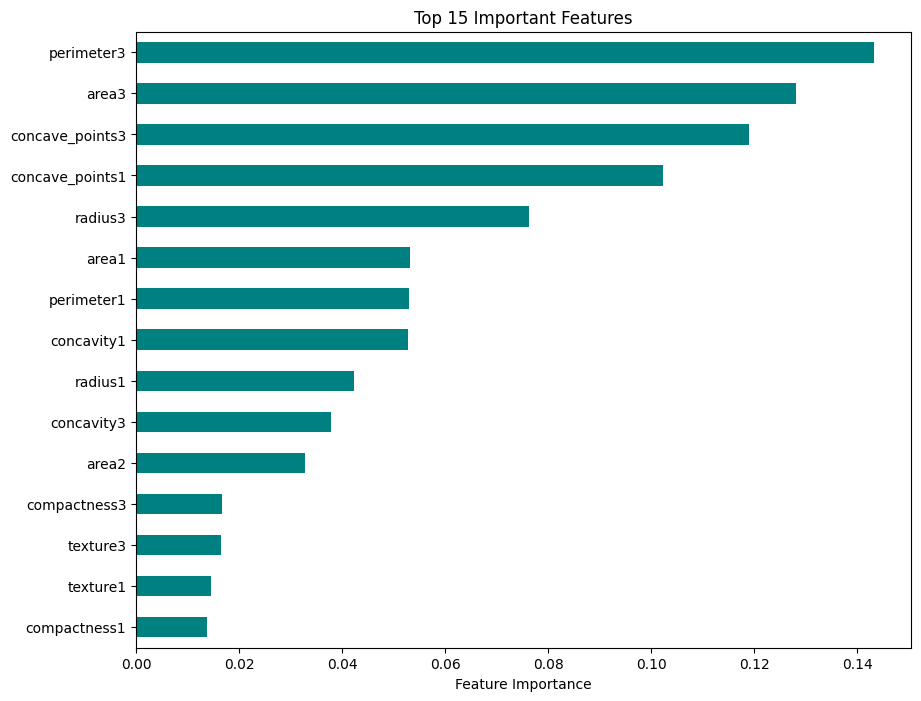

In [8]:
# Method 3: Random Forest feature importance

from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X, y)

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 8))

importance.head(15).sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Top 15 Important Features")
plt.xlabel("Feature Importance")
plt.show()

In [ ]:
# Feature scaling
# features have very different numerical ranges.

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X)

In [ ]:
# Encode the target
# Convert B and M into numerical labels.

y = y["Diagnosis"].map({
        "B": 0,
        "M": 1
    }).squeeze()

# from sklearn.preprocessing import LabelEncoder

# le = LabelEncoder()
# y = le.fit_transform(y["Diagnosis"])

In [ ]:
import nbimporter
from loading_and_inspection import breast_cancer_dataset
from sklearn.model_selection import train_test_split

def get_breast_cancer():

    # fetching dataset
    X, y = breast_cancer_dataset()

    # encoding lables
    y = y["Diagnosis"].map({
        "B": 0,
        "M": 1
    }).squeeze()

    # scaling the features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # spliting the scaled feature and encoded target into training and testing
    return train_test_split(
        X_scaled,  y,      # Convert single-column target DataFrame to Series
        test_size=0.2,       # 20% testing, 80% training
        random_state=42,     # Reproducibility
        shuffle=True,
        stratify=y
    )